# Bayes stream: a Bayesian generative model of slow wind and stream arrivals (models.bayes_stream)

Structural model v3: a slow wind that relaxes from the current speed towards an ambient level,
plus hierarchical streams (a Poisson count of arrivals, stick-breaking arrival times, each
event's peak excess and decay with partial pooling), with AR(1) noise. Posterior by NumPyro
NUTS. As first specified (smooth max of the slow wind and the streams, per-event rise widths)
NUTS doesn't mix; the study fits the **additive rule with the rise width at its population
value**. Also fitted with the arrivals latent (summed out, `bayes latent`) and its mean path
used as the linear model's regressor (`linear + bayes latent`). Six yearly folds, not built. Study `python -m training.bayes_stream`; write-up
`docs/bayes_stream.md`.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training import bayes_stream as tbs
from training import model_diagnostics as dg

d = pd.read_csv(tbs.EXPERIMENTS / "bayes_stream.csv", dtype={"fold": str})
p = pd.read_csv(tbs.EXPERIMENTS / "bayes_stream_params.csv", dtype={"fold": str})
ref = d[d.variant == "reference"].set_index("fold")
rows = {}
for v, g in d.groupby("variant"):
    g = g.set_index("fold")
    rel = g["all"] / ref["all"]
    rows[v] = {"vs reference %": 100 * (np.exp(np.log(rel).mean()) - 1),
               "folds won": int((rel < 1).sum()),
               **{f"{r} %": 100 * (np.exp(np.log(g[r] / ref[r]).mean()) - 1)
                  for r in dg.RUN_REGIMES}}
pd.DataFrame(rows).T.sort_values("vs reference %").round(2)

,vs reference %,folds won,CME %,stream arrival %,fast stream %,intermediate %,slow wind %
linear + bayes latent,-0.23,3.0,-0.17,-0.12,-0.96,-0.15,-0.52
linear + bayes,-0.09,3.0,-0.09,-0.14,-0.15,-0.11,-0.05
reference,0.00,0.0,0.00,0.00,0.00,0.00,0.00
bayes official,5.29,0.0,6.00,5.61,8.01,-3.69,-2.83
bayes latent,7.50,0.0,10.26,17.90,31.64,-10.07,-25.00
bayes,9.97,0.0,13.23,20.83,36.06,-10.12,-26.59
slow wind only,20.95,0.0,25.95,43.55,54.02,-2.52,-37.81


## Six folds: S_final against the submitted model

Geometric mean over the folds of the S_final ratio, overall and within each run regime. Keep rule
(set before running): more than 1% better and winning at least 4 of 6 folds.

variant,reference,linear + bayes,linear + bayes latent,bayes official,bayes latent,bayes,slow wind only
fold,,,,,,,
2019,60.01,59.74,59.25,63.01,64.32,66.61,72.83
2020,68.86,68.62,68.13,70.55,71.66,75.27,85.34
2021,84.93,84.89,84.99,89.96,91.73,92.65,101.84
2022,88.89,89.01,89.38,100.43,100.33,102.24,108.41
2023,111.38,111.44,111.36,116.56,120.42,120.61,128.99
2024,107.81,107.92,108.15,108.98,113.14,115.65,132.45


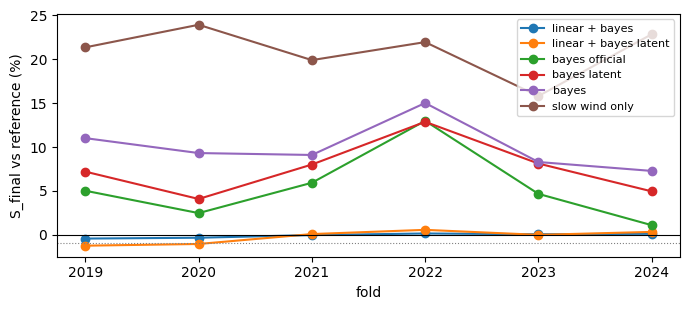

In [2]:
wide = d.pivot(index="fold", columns="variant", values="all")
pct = (wide.div(wide["reference"], axis=0) - 1) * 100
order = ["reference", "linear + bayes", "linear + bayes latent", "bayes official",
         "bayes latent", "bayes", "slow wind only"]
fig, ax = plt.subplots(figsize=(7, 3.2))
for v in order[1:]:
    ax.plot(pct.index, pct[v], marker="o", label=v)
ax.axhline(0, color="k", lw=0.8)
ax.axhline(-1, color="grey", ls=":", lw=0.8)
ax.set_ylabel("S_final vs reference (%)")
ax.set_xlabel("fold")
ax.legend(fontsize=8)
plt.tight_layout()
wide[order].round(2)

## Convergence and posterior per fold (observed-arrival fit)

In [3]:
po = p[p.fit == "observed"].set_index("fold")
conv = ["windows kept", "events", "fit s", "r_hat max", "ess min", "r_hat max events",
        "ess min events", "divergences", "tree depth hit", "arrivals r_hat max",
        "arrivals ess min", "speed leapfrog mean"]
post = ["ambient w0", "rho_up", "rho_dn", "rho_eta", "sigma_eta", "Lambda base /84h",
        "excess median km/s", "sigma_E", "rise width h", "decay h", "sigma_D",
        "ppc arrivals observed", "ppc arrivals expected", "ppc coverage 80"]
display(po[conv].T.round(3))
po[post].T.round(3)

fold,2019,2020,2021,2022,2023,2024
windows kept,317.000,428.000,518.000,605.000,688.000,761.000
events,87.000,96.000,119.000,152.000,182.000,192.000
fit s,303.456,364.944,367.586,455.968,480.744,460.966
r_hat max,1.008,1.187,1.033,1.029,1.056,1.016
ess min,131.104,13.826,118.499,54.091,32.110,84.858
r_hat max events,1.013,1.150,1.020,1.020,1.137,1.085
ess min events,58.554,14.933,157.621,43.298,20.829,30.530
divergences,0.000,0.000,0.000,0.000,0.000,0.000
tree depth hit,0.000,0.000,0.000,0.000,0.000,0.000
arrivals r_hat max,1.001,1.006,1.005,1.006,1.001,1.003


fold,2019,2020,2021,2022,2023,2024
ambient w0,-0.325,-0.316,-0.371,-0.247,-0.261,-0.205
rho_up,0.984,0.985,0.984,0.984,0.985,0.985
rho_dn,0.973,0.971,0.975,0.979,0.978,0.977
rho_eta,0.990,0.990,0.989,0.987,0.986,0.985
sigma_eta,10.328,9.872,9.917,10.639,11.011,11.021
Lambda base /84h,0.211,0.170,0.184,0.206,0.223,0.214
excess median km/s,136.113,143.812,151.050,141.538,142.001,136.531
sigma_E,0.403,0.380,0.339,0.328,0.332,0.328
rise width h,1.723,1.980,2.217,1.882,1.876,1.767
decay h,129.616,134.535,124.171,152.655,151.402,164.074


## Latent arrivals: the fit and the regressor
`bayes latent` sums the arrivals out instead of taking the detected ones as data (one arrival
per 84 h window at most, 300 + 200 draws per chain). Below: S_final against the reference per
fold for the two linear + bayes variants and the two generative models; then the latent fit's
convergence and posterior next to the observed fit's.

variant,linear + bayes,linear + bayes latent,bayes,bayes latent
fold,,,,
2019,-0.44,-1.25,11.01,7.19
2020,-0.35,-1.06,9.31,4.07
2021,-0.05,0.07,9.09,8.00
2022,0.14,0.55,15.02,12.87
2023,0.05,-0.02,8.29,8.11
2024,0.10,0.32,7.27,4.94


crps              coverage 80              arrival AUC             
variant   bayes bayes latent       bayes bayes latent       bayes bayes latent
fold                                                                          
2019     26.273       24.977       0.902        0.901       0.829        0.843
2020     31.271       30.041       0.810        0.817       0.709        0.692
2021     36.206       36.067       0.781        0.809       0.748        0.642
2022     37.370       38.054       0.785        0.796       0.633        0.569
2023     34.080       33.948       0.825        0.826       0.533        0.518
2024     39.155       39.892       0.793        0.774       0.692        0.643

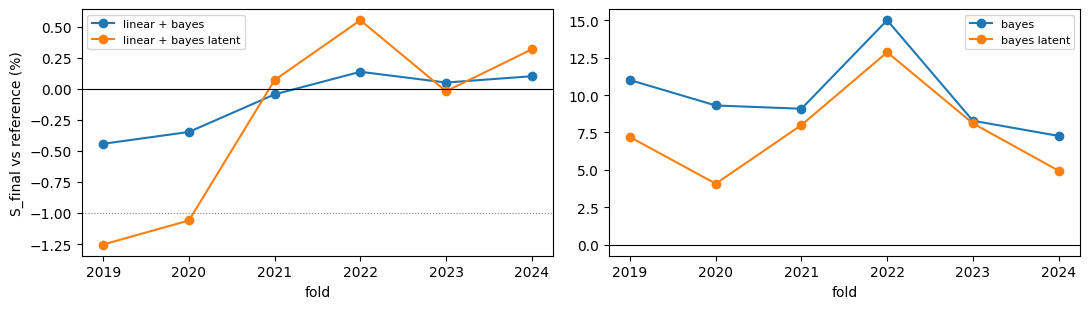

In [4]:
cmp = pct[["linear + bayes", "linear + bayes latent", "bayes", "bayes latent"]]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, cols in zip(axes, (cmp.columns[:2], cmp.columns[2:]), strict=True):
    for v in cols:
        ax.plot(cmp.index, cmp[v], marker="o", label=v)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xlabel("fold")
    ax.legend(fontsize=8)
axes[0].axhline(-1, color="grey", ls=":", lw=0.8)
axes[0].set_ylabel("S_final vs reference (%)")
plt.tight_layout()
skill = d[d.variant.isin(["bayes", "bayes latent"])].pivot(
    index="fold", columns="variant", values=["crps", "coverage 80", "arrival AUC"])
display(cmp.round(2))
skill.round(3)

In [5]:
pl = p[p.fit == "latent"].set_index("fold")
display(pl[["fit s", "r_hat max", "ess min", "divergences", "tree depth hit",
            "leapfrog mean"]].T.round(3))
both = ["ambient w0", "rho_up", "rho_dn", "Lambda base /84h", "excess median km/s",
        "rise width h", "decay h", "ppc arrivals observed", "ppc arrivals expected",
        "ppc coverage 80"]
(pd.concat({"observed": po[both], "latent": pl[both]}, axis=1).swaplevel(axis=1)
 .sort_index(axis=1).T.round(3))

fold,2019,2020,2021,2022,2023,2024
fit s,1219.940,1745.210,2729.400,2768.890,3346.260,2744.870
r_hat max,1.015,1.005,1.010,1.014,1.005,1.005
ess min,140.072,283.251,291.583,245.670,334.008,253.455
divergences,0.000,0.000,0.000,0.000,0.000,0.000
tree depth hit,0.000,0.000,0.000,0.000,0.000,0.000
leapfrog mean,21.520,19.720,23.480,20.600,30.620,21.360


fold                               2019     2020     2021     2022     2023  \
Lambda base /84h      latent      0.722    0.690    0.598    0.586    0.437   
                      observed    0.211    0.170    0.184    0.206    0.223   
ambient w0            latent     -0.019   -0.037   -0.037    0.033    0.184   
                      observed   -0.325   -0.316   -0.371   -0.247   -0.261   
decay h               latent     49.924   52.619   45.724   58.261   63.820   
                      observed  129.616  134.535  124.171  152.655  151.402   
excess median km/s    latent    116.351  110.132  112.407  120.867  117.476   
                      observed  136.113  143.812  151.050  141.538  142.001   
ppc arrivals expected latent    124.440  161.600  181.070  207.070  202.310   
                      observed   71.080   79.610   98.880  125.760  151.930   
ppc arrivals observed latent     73.000   82.000   99.000  128.000  154.000   
                      observed   73.000   82.000   99.000  128.000  154.000   
ppc coverage 80       latent      0.824    0.828    0.828    0.822    0.815   
                      observed    0.809    0.817    0.816    0.808    0.807   
rho_dn                latent      0.975    0.973    0.973    0.976    0.977   
                      observed    0.973    0.971    0.975    0.979    0.978   
rho_up                latent      0.975    0.976    0.979    0.979    0.979   
                      observed    0.984    0.985    0.984    0.984    0.985   
rise width h          latent      1.090    1.120    1.076    1.051    0.694   
                      observed    1.723    1.980    2.217    1.882    1.876   

fold                               2024  
Lambda base /84h      latent      0.419  
                      observed    0.214  
ambient w0            latent      0.124  
                      observed   -0.205  
decay h               latent     55.853  
                      observed  164.074  
excess median km/s    latent    115.160  
                      observed  136.531  
ppc arrivals expected latent    218.630  
                      observed  160.570  
ppc arrivals observed latent    164.000  
                      observed  164.000  
ppc coverage 80       latent      0.819  
                      observed    0.806  
rho_dn                latent      0.976  
                      observed    0.977  
rho_up                latent      0.980  
                      observed    0.985  
rise width h          latent      0.685  
                      observed    1.767

### 2024: the latent fit's mean path by regime

Recomputed from the cached 2024 latent posterior (the study caches only the observed fit's
forecasts).

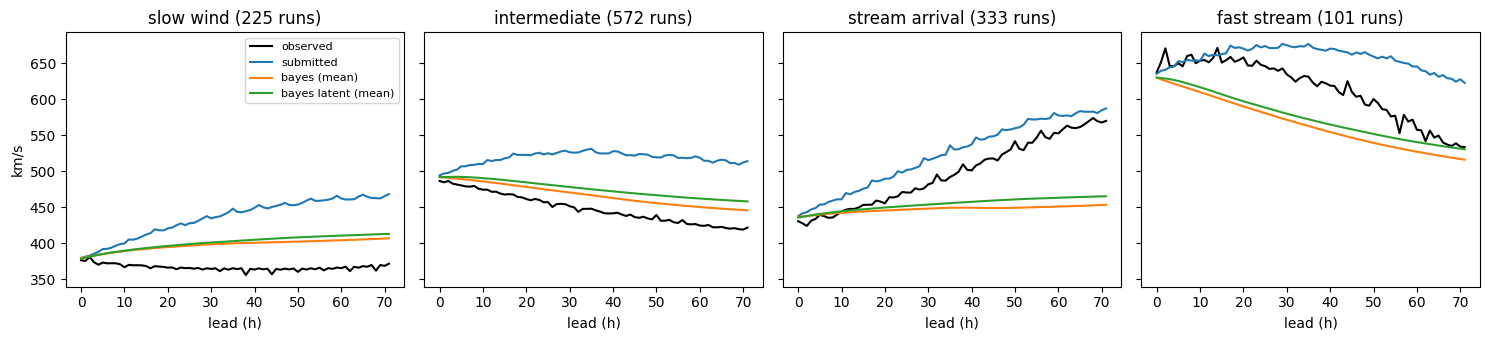

In [6]:
from models import bayes_stream as bs

data = dg.Data()
start, end = next((a, b) for a, b in tbs.YEARLY if a.year == 2024)
ff = tbs.fold_fit(data, start)
val = data.runs6[(data.runs6 >= start) & (data.runs6 < end)]
x_val = ff["table"].loc[val, ff["cols"]].to_numpy(dtype=float)
inp_val = ff["model"].prepare(data.values, data.series.index.get_indexer(val), x_val)
lat = bs.summarize_paths(dict(np.load(tbs.CACHE_DIR / "2024_latent_draws.npz")), inp_val,
                         tbs.FITS["latent"], ff["model"].table, n_paths=tbs.N_PATHS)
z = np.load(tbs.CACHE_DIR / "2024_parts.npz")
assert (z["t0s"] == val.asi8).all()
regime = z["regime"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5), sharey=True)
for ax, r in zip(axes, ("slow wind", "intermediate", "stream arrival", "fast stream"),
                 strict=True):
    m = regime == r
    ax.plot(np.nanmean(z["obs"][m], 0), "k", label="observed")
    ax.plot(z["f_ref"][m].mean(0), label="submitted")
    ax.plot(z["mean"][m].mean(0), label="bayes (mean)")
    ax.plot(lat["mean"][m].mean(0), label="bayes latent (mean)")
    ax.set_title(f"{r} ({m.sum()} runs)")
    ax.set_xlabel("lead (h)")
axes[0].legend(fontsize=8)
axes[0].set_ylabel("km/s")
plt.tight_layout()

## The sampler study (2024 fold)

How the speed block got from no mixing to converging. One fit per run with
`python -m training.bayes_stream --sampler LABEL`, without scoring; 2 chains each.

In [7]:
runs = [  # label, what changed
    ("smoke", "smooth max, per-event rise; centred MAP start; 30 + 30"),
    ("smoke2", "non-centred MAP start; 30 + 30"),
    ("medium", "non-centred MAP start; 200 + 100"),
    ("arrivals", "arrival block only; 200 + 100"),
    ("speed", "speed block only; 200 + 100"),
    ("speed_ncE", "speed block, non-centred log_E"),
    ("speed_hess", "speed block, mass matrix from the Hessian"),
    ("speed_hess_ncE", "Hessian start + non-centred log_E"),
    ("fixed_rise_hess", "rise width at its population value; 200 + 100"),
    ("fixed_rise_full", "the same, 500 + 500"),
    ("fixed_rise_add", "additive rule, fixed rise; 500 + 500"),
]
table = []
for label, what in runs:
    r = json.loads((tbs.CACHE_DIR / f"sampler_{label}.json").read_text("utf-8"))
    info = r.get("speed") or r.get("arrivals") or r.get("all") or r  # block results or flat
    table.append({"run": label, "setup": what, "fit s": info.get("fit s"),
                  "leapfrog": info["leapfrog mean"], "tree depth hit": info["tree depth hit"],
                  "R-hat globals": info["r_hat max"], "R-hat marks": info.get("r_hat max events"),
                  "ESS min": info["ess min"]})
pd.set_option("display.max_colwidth", 60)
pd.DataFrame(table).set_index("run").round(3)

,setup,fit s,leapfrog,tree depth hit,R-hat globals,R-hat marks,ESS min
run,,,,,,,
smoke,"smooth max, per-event rise; centred MAP start; 30 + 30",330.112,255.000,1.0,20.845,22.155,1.019
smoke2,non-centred MAP start; 30 + 30,326.634,255.000,1.0,3.238,17.719,1.138
medium,non-centred MAP start; 200 + 100,1409.345,255.000,1.0,6.150,8.055,1.036
arrivals,arrival block only; 200 + 100,70.831,14.080,0.0,1.012,NaN,111.626
speed,speed block only; 200 + 100,914.238,255.000,1.0,3.843,6.186,1.064
speed_ncE,"speed block, non-centred log_E",935.557,255.000,1.0,4.379,8.968,1.106
speed_hess,"speed block, mass matrix from the Hessian",912.219,255.000,1.0,1.914,3.700,1.590
speed_hess_ncE,Hessian start + non-centred log_E,898.404,255.000,1.0,2.320,5.685,1.195
fixed_rise_hess,rise width at its population value; 200 + 100,270.040,62.840,0.0,1.384,2.258,4.207


## Curvature at the MAP start (speed block, smooth max, per-event rise)

The Hessian of NUTS's potential in its unconstrained space. Raw, the well-determined globals set
the step size and the event decays are the flattest directions (condition about 10^6); scaled by
the diagonal (what an adapted diagonal mass matrix leaves) the condition is 408, the flattest
directions being each event's peak excess against its rise width.

In [8]:
c = json.loads((tbs.CACHE_DIR / "sampler_curvature_speed.json").read_text("utf-8"))
for name in ("raw", "scaled"):
    r = c[name]
    print(f"{name}: eig max {r['eig max']:.4g}, min positive {r['eig min positive']:.4g}, "
          f"condition {r['condition']:.3g}, negative {r['negative']}")
    for part in ("stiffest", "flattest"):
        for e in r[part][:3]:
            print(f"  {part:9s} {e['eig']:10.4g}  {e['sites']}")

raw: eig max 9.737e+04, min positive 0.09593, condition 1.01e+06, negative 4
  stiffest   9.737e+04  {'sigma_eta': 1.0}
  stiffest        3172  {'w_a': 0.942, 'rho_up': 0.031, 'log_E': 0.021}
  stiffest        1190  {'rho_up': 0.686, 'w_a': 0.171, 'log_E': 0.105, 'log_R': 0.029}
  flattest     0.09593  {'log_D': 0.996}
  flattest      0.1036  {'log_D': 0.998}
  flattest      0.1162  {'log_D': 0.996}
scaled: eig max 3.141, min positive 0.007701, condition 408, negative 4
  stiffest       3.141  {'w_a': 0.556, 'log_E': 0.203, 'log_R': 0.147, 'rho_up': 0.072}
  stiffest       2.396  {'w_D': 0.393, 'log_D': 0.305, 'mu_D': 0.194, 'log_R': 0.092}
  stiffest       2.259  {'log_R': 0.51, 'log_D': 0.427, 'log_E': 0.06}
  flattest    0.007701  {'log_R': 0.5, 'log_E': 0.5}
  flattest     0.01575  {'w_a': 0.954, 'log_E': 0.023}
  flattest     0.03896  {'log_E': 0.5, 'log_R': 0.499}


## The hidden-stream mode: smooth max against the additive rule

Each event's peak excess E, median of chain 1 against chain 2 (fixed rise width, Hessian start,
500 + 500). Under the smooth max a stream below the slow wind leaves its excess unidentified,
and two events sit in different modes in the two chains; under the additive rule every event
agrees.

smooth max: 6 of 192 events above R-hat 1.1; additive: worst event R-hat 1.085


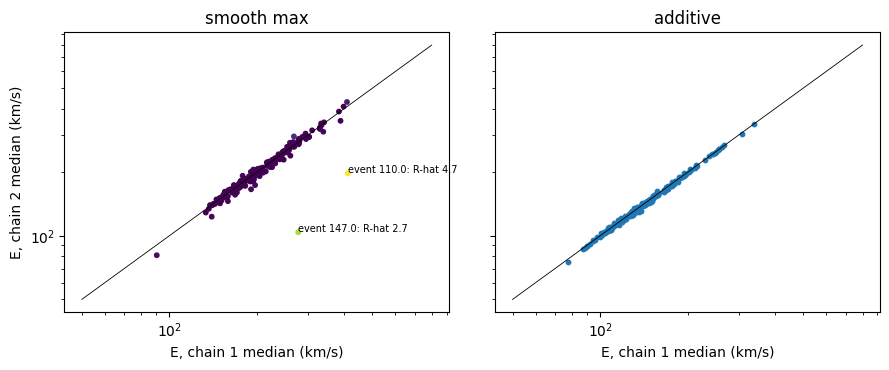

In [9]:
ev_max = pd.read_csv(tbs.CACHE_DIR / "sampler_fixed_rise_events_events.csv")
r_add = json.loads((tbs.CACHE_DIR / "sampler_fixed_rise_add.json").read_text("utf-8"))["speed"]
med_add = np.exp(np.asarray(r_add["event chain medians"]["log_E"]))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharex=True, sharey=True)
axes[0].scatter(ev_max["med E c0"], ev_max["med E c1"], s=10,
                c=np.minimum(ev_max["r_hat E"], 3), cmap="viridis")
for _, e in ev_max[ev_max["r_hat E"] > 2].iterrows():
    axes[0].annotate(f"event {e['event']}: R-hat {e['r_hat E']:.1f}",
                     (e["med E c0"], e["med E c1"]), fontsize=7)
axes[1].scatter(med_add[0], med_add[1], s=10)
for ax, t in zip(axes, ("smooth max", "additive"), strict=True):
    lim = [50, 800]
    ax.plot(lim, lim, "k", lw=0.6)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(t)
    ax.set_xlabel("E, chain 1 median (km/s)")
axes[0].set_ylabel("E, chain 2 median (km/s)")
plt.tight_layout()
print(f"smooth max: {(ev_max['r_hat max'] > 1.1).sum()} of {len(ev_max)} events above "
      f"R-hat 1.1; additive: worst event R-hat {r_add['r_hat max events']:.3f}")

## Mean forecast and observation by lead and run regime, 2024 fold

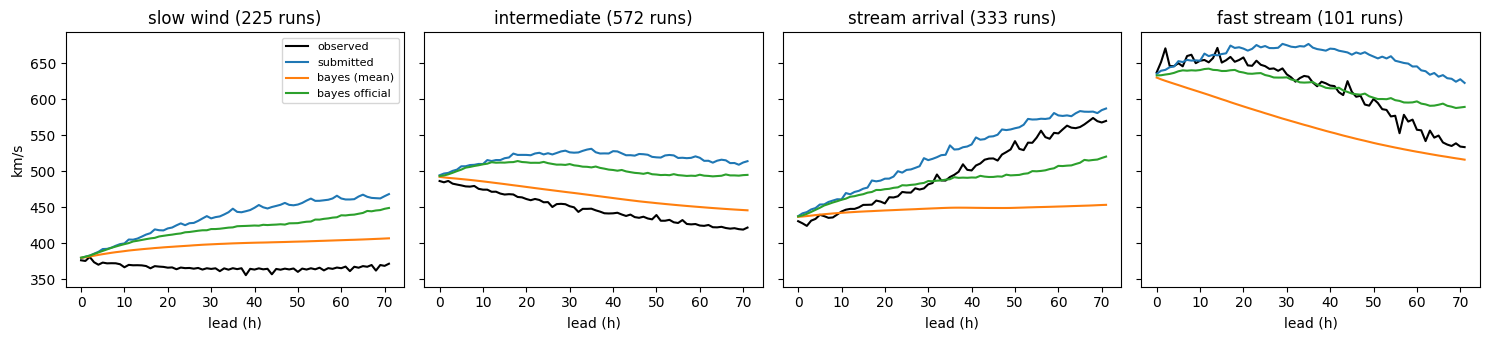

In [10]:
z = np.load(tbs.CACHE_DIR / "2024_parts.npz")
regime = z["regime"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5), sharey=True)
for ax, r in zip(axes, ("slow wind", "intermediate", "stream arrival", "fast stream"),
                 strict=True):
    m = regime == r
    ax.plot(np.nanmean(z["obs"][m], 0), "k", label="observed")
    ax.plot(z["f_ref"][m].mean(0), label="submitted")
    ax.plot(z["mean"][m].mean(0), label="bayes (mean)")
    ax.plot(z["official"][m].mean(0), label="bayes official")
    ax.set_title(f"{r} ({m.sum()} runs)")
    ax.set_xlabel("lead (h)")
axes[0].legend(fontsize=8)
axes[0].set_ylabel("km/s")
plt.tight_layout()

## Uncertainty and arrival skill, 2024 fold

fold           2019    2020    2021    2022    2023    2024         2019  \
variant       bayes   bayes   bayes   bayes   bayes   bayes bayes latent   
crps         26.273  31.271  36.206  37.370  34.080  39.155       24.977   
coverage 80   0.902   0.810   0.781   0.785   0.825   0.793        0.901   
arrival AUC   0.829   0.709   0.748   0.633   0.533   0.692        0.843   

fold                2020         2021         2022         2023         2024  
variant     bayes latent bayes latent bayes latent bayes latent bayes latent  
crps              30.041       36.067       38.054       33.948       39.892  
coverage 80        0.817        0.809        0.796        0.826        0.774  
arrival AUC        0.692        0.642        0.569        0.518        0.643  


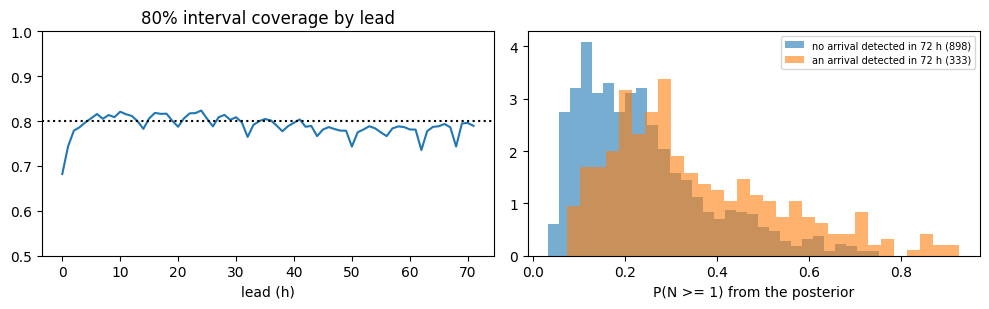

In [11]:
ok = ~np.isnan(z["obs"])
cover = ((z["obs"] >= z["q10"]) & (z["obs"] <= z["q90"]))
cov_lead = np.where(ok, cover, np.nan)
clean = z["m_lab"].all(axis=1)
any_obs = z["n_lab"][clean].sum(axis=1) > 0
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(np.nanmean(cov_lead, 0))
axes[0].axhline(0.8, color="k", ls=":")
axes[0].set_ylim(0.5, 1)
axes[0].set_title("80% interval coverage by lead")
axes[0].set_xlabel("lead (h)")
for o in (False, True):
    axes[1].hist(z["p_any"][clean][any_obs == o], bins=30, alpha=0.6, density=True,
                 label=f"{'an' if o else 'no'} arrival detected in 72 h ({(any_obs == o).sum()})")
axes[1].set_xlabel("P(N >= 1) from the posterior")
axes[1].legend(fontsize=7)
plt.tight_layout()
print(d[d.variant.isin(["bayes", "bayes latent"])][["fold", "variant", "crps", "coverage 80",
      "arrival AUC"]].set_index(["fold", "variant"]).round(3).T)

## Conclusion

Not built (2026-11-15; latent arrivals 2026-11-16).
- **As a regressor in the submitted linear model it ties** (`linear + bayes` −0.09%, 3 of 6 folds); on its own the generative model loses in every fold (`bayes official` +5.3%, the predictive mean +10.0%).
- **Good in quiet wind, bad around streams.** The predictive mean is 27% better than the reference in slow wind and 10% better in intermediate wind, but 21% worse at stream arrivals and 36% worse in fast streams: the arrival skill is modest (AUC 0.69). Its uncertainty is calibrated (80% coverage 0.82, CRPS 34 km/s).
- **Sampling needed the model changed.** As specified (smooth max, per-event rise widths) NUTS doesn't mix: each event's excess trades off against its rise width, and under the smooth max a stream below the slow wind leaves its excess unidentified, a second mode. The study uses the additive rule with a population rise width, the non-centred MAP start, a Hessian-started mass matrix and the posterior's exact split into an arrival and a speed block. 2020 and 2023 are still not fully mixed (R-hat 1.19 and 1.06).

- **Latent arrivals help slightly, not enough.** `linear + bayes latent` is −0.23% (3 of 6 folds): −1.25% and −1.06% on 2019 and 2020, worse on 2022 and 2024. Alone, `bayes latent` beats `bayes` on every fold (+7.5% against +10.0%) but detects arrivals less well (AUC 0.65 against 0.69); it expects about 1.6 times the detected arrivals, smaller and shorter. Every latent fit converged (R-hat at most 1.015).

The follow-up: the fitted model's run-by-run quantities (ambient level, slow-wind path, arrival probability by lead, expected stream contribution) as separate regressors in the linear model, so it can take the quiet-wind part without the stream amplitudes (`training.bayes_features`).